# EMTP traveling-brain QSM: analysis

Results recomputed from the regional values in `data/`, with the figures. The same functions back `analysis/abstract_numbers.py` and the figure scripts in `figures/src/`.

In [1]:
import sys; sys.path.insert(0, 'analysis')
import emtp, numpy as np, pandas as pd
pd.set_option('display.precision', 3)
reg = emtp.regions(); acq = emtp.acquisitions(); pipes = emtp.pipelines()
print(reg.pipeline.nunique(), 'pipelines,', reg[['pipeline','acquisition']].drop_duplicates().shape[0], 'maps,', acq.shape[0], 'acquisitions')

638 pipelines, 45927 maps, 72 acquisitions


## Dataset

In [2]:
acq.groupby(['subject', 'scanner']).size().unstack(fill_value=0)

scanner,site1-achieva,site1-elition,site4-skyra,site5-mr750,site5-prisma,site6-ingenia
subject,,,,,,
s002001,6,0,0,0,0,0
s003001,6,0,0,0,0,0
s004001,6,0,6,0,0,0
s005001,0,6,0,6,6,0
s005002,6,0,0,6,6,0
s006001,6,0,0,0,0,6


In [3]:
pipes.groupby('n_steps').size().rename({1: 'end-to-end', 2: 'field map + combined', 3: 'three-step'})

n_steps
end-to-end                4
field map + combined     10
three-step              624
dtype: int64

## Regions per fit

A region enters a scan’s values only if at least 90% of it lies inside that reconstruction; a pair is fitted on the regions present in both scans.

In [4]:
fits = emtp.pair_fits(reg)
ok = fits[fits.excluded == '']
print(fits.excluded.value_counts())
ok.n_rois.value_counts().sort_index()

excluded
             160293
slope_cap       462
Name: count, dtype: int64


n_rois
11        6
13        3
14       18
15       33
16       31
17     1769
18    24704
19     6034
20    34095
21    19978
22     3006
23     7076
24     3698
25    59842
Name: count, dtype: int64

In [5]:
# which regions drop out, by scanner and protocol (share of maps missing the region)
pres = reg.groupby(['acquisition'])['region'].value_counts().unstack(fill_value=0)
maps = reg.groupby('acquisition').pipeline.nunique()
miss = 1 - pres.div(maps, axis=0)
miss = miss.join(acq.set_index('acquisition')[['scanner', 'protocol']]).groupby(['scanner', 'protocol']).mean()
miss.loc[:, (miss > 0.05).any()].round(2)

Brain-Stem  Left-Amygdala  Left-Cerebellum-Cortex  \
scanner       protocol                                                      
site1-achieva bridge          0.30           0.05                    0.56   
              local           0.22           0.10                    0.39   
site1-elition bridge          0.34           0.00                    0.49   
              local           0.25           0.00                    0.35   
site4-skyra   bridge          0.85           0.00                    0.98   
              local           0.97           0.00                    0.97   
site5-mr750   bridge          0.21           0.00                    0.35   
              local           0.18           0.00                    0.30   
site5-prisma  bridge          0.97           0.00                    0.99   
              local           0.13           0.00                    0.34   
site6-ingenia bridge          0.26           0.00                    0.35   
              local           0.26           0.17                    0.35   

                        Left-Cerebellum-WM  Left-Cerebral-Cortex  \
scanner       protocol                                             
site1-achieva bridge                  0.18                  0.40   
              local                   0.00                  0.40   
site1-elition bridge                  0.06                  0.43   
              local                   0.00                  0.43   
site4-skyra   bridge                  0.97                  0.35   
              local                   0.97                  0.43   
site5-mr750   bridge                  0.13                  0.35   
              local                   0.00                  0.39   
site5-prisma  bridge                  0.98                  0.39   
              local                   0.00                  0.39   
site6-ingenia bridge                  0.00                  0.43   
              local                   0.00                  0.43   

                        Right-Cerebellum-Cortex  Right-Cerebellum-WM  \
scanner       protocol                                                 
site1-achieva bridge                       0.52                 0.18   
              local                        0.37                 0.00   
site1-elition bridge                       0.55                 0.23   
              local                        0.35                 0.00   
site4-skyra   bridge                       1.00                 0.99   
              local                        1.00                 0.97   
site5-mr750   bridge                       0.33                 0.08   
              local                        0.35                 0.00   
site5-prisma  bridge                       0.98                 0.74   
              local                        0.32                 0.00   
site6-ingenia bridge                       0.26                 0.00   
              local                        0.26                 0.00   

                        Right-Cerebral-Cortex  
scanner       protocol                         
site1-achieva bridge                     0.40  
              local                      0.40  
site1-elition bridge                     0.40  
              local                      0.43  
site4-skyra   bridge                     0.35  
              local                      0.43  
site5-mr750   bridge                     0.35  
              local                      0.39  
site5-prisma  bridge                     0.35  
              local                      0.39  
site6-ingenia bridge                     0.43  
              local                      0.43

## Agreement between scans (Figure 3)

Per pipeline: median over its scan pairs. Then the distribution across pipelines. The primary measure is |a − 1| for both test-retest and inter-scanner pairs; secondary measures are R², the limits of agreement after correcting each pair for its fitted scaling (corrected LoA), and for test-retest the SD of a (see `docs/decisions.md`).

In [6]:
pp = {m: emtp.per_pipeline(fits, m) for m in ('abs_slope_dev', 'r2', 'ba_loa_ppm', 'ba_loa_corrected_ppm')}
d = 100 * pp['abs_slope_dev']
pd.DataFrame({'p25': d.quantile(.25), 'median': d.median(), 'p75': d.quantile(.75), 'p95': d.quantile(.95),
              'pipelines > 25%': (d > 25).sum()}).loc[['test_retest', 'inter_scanner']].round(1)

p25  median   p75   p95  pipelines > 25%
comparison    protocol                                          
test_retest   bridge    1.9     2.2   2.6   3.6                0
              local     1.2     1.4   1.8   2.7                0
inter_scanner bridge    5.2     6.4   8.6  21.8               29
              local     4.2     7.0  11.1  28.0               38

In [7]:
pd.DataFrame({'median R²': pp['r2'].median(), 'median LoA (± ppb)': 1000 * pp['ba_loa_ppm'].median(),
              'median corrected LoA (± ppb)': 1000 * pp['ba_loa_corrected_ppm'].median()}).loc[['test_retest', 'inter_scanner', 'inter_protocol']].round(3)

median R²  median LoA (± ppb)  \
comparison     protocol                                         
test_retest    bridge               0.991               8.730   
               local                0.996               5.609   
inter_scanner  bridge               0.953              19.052   
               local                0.959              17.498   
inter_protocol local_vs_bridge      0.980              12.233   

                                median corrected LoA (± ppb)  
comparison     protocol                                       
test_retest    bridge                                  8.307  
               local                                   5.317  
inter_scanner  bridge                                 17.969  
               local                                  16.218  
inter_protocol local_vs_bridge                        11.578

### By scanner pair (inter-scanner, all pipelines)

In [8]:
isc = ok[ok.comparison == 'inter_scanner']
(100 * isc.groupby(['scanner_x', 'scanner_y', 'protocol']).abs_slope_dev.median()).unstack().round(1)

protocol                     bridge  local
scanner_x     scanner_y                   
site1-achieva site4-skyra       8.9    8.4
              site5-mr750       9.5    6.6
              site5-prisma      8.6    6.5
              site6-ingenia     4.0    4.2
site1-elition site5-mr750       8.1    5.7
              site5-prisma      4.7    8.6
site5-mr750   site5-prisma      6.1    7.0

### By pipeline step (inter-scanner median |a − 1|, %)

In [9]:
isc3 = isc.merge(pipes, on='pipeline')
for step in ('field_mapping', 'background_removal'):
    display((100 * isc3.groupby([step, 'protocol']).abs_slope_dev.median()).unstack().round(1))
(100 * isc3.groupby(['dipole_inversion', 'protocol']).abs_slope_dev.median()).unstack().sort_values('bridge').round(1)

protocol,bridge,local
field_mapping,,
laplacian-qsmrs,7.0,7.4
romeo-qsmrs,6.2,5.8


protocol,bridge,local
background_removal,,
bfrnet,7.0,9.5
harperella-qsmrs,9.4,10.5
iharperella-qsmrs,7.3,5.4
iqfm,6.3,6.3
ismv-qsmrs,5.4,6.2
lbv-qsmrs,8.1,11.4
pdf-qsmrs,7.9,9.0
resharp-qsmrs,5.5,4.9
sharp-qsmrs,4.2,4.4


protocol,bridge,local
dipole_inversion,,
iqsm-plus,4.3,14.2
qsmnet,5.1,12.4
whqsm-qsmrs,5.1,4.0
ukb-qsm,5.4,9.1
amp-pe-qsmrs,5.5,5.3
modl-qsm,5.6,8.3
heidi-qsmrs,5.7,4.7
ilsqr-qsmrs,5.8,5.3
lpcnn,5.8,5.9


## Sources of variability (Figure 4)

Each bar is the SD of a region's mean χ when one factor varies and the others are fixed, median over pipelines (and over subjects and scanners within a pipeline). Rescan: SD over the three runs. Protocol: for each subject and scanner, the SD of the run-averaged values of the bridge and local protocols (two values), so it includes any scaling difference between the protocols. Scanner: SD over the scanners a subject was scanned on, same protocol. Pipeline: SD over all pipelines of the run-averaged values, same subject, scanner and protocol. Between subjects: SD over the subjects scanned on the reference scanner. Bars are not corrected for scaling (see `docs/decisions.md`).

In [10]:
pd.concat({r: emtp.spread(reg, r) for r in ('Caudate', 'Pallidum', 'Putamen', 'Thalamus')}, axis=1).round(1)

Caudate             Pallidum             Putamen              \
                  bridge local  both   bridge local  both  bridge local  both   
rescan               1.7   1.0   1.3      2.4   2.0   2.1     1.3   1.0   1.1   
protocol             NaN   NaN   2.1      NaN   NaN   3.0     NaN   NaN   2.5   
scanner              2.6   4.1   3.0      6.5   6.8   6.9     2.9   4.0   3.3   
pipeline            21.5  20.8  21.1     29.2  34.3  31.3    18.0  19.2  18.4   
between_subjects    13.2  12.9  13.1     29.3  27.6  28.6    19.3  17.6  18.5   

                 Thalamus              
                   bridge local  both  
rescan                1.0   1.0   1.0  
protocol              NaN   NaN   1.6  
scanner               3.2   3.2   3.2  
pipeline             17.0  19.8  17.6  
between_subjects      5.9   4.8   5.3

## Key results

The values quoted in the abstract, from `results/numbers.json` (written by `analysis/abstract_numbers.py`).

In [11]:
import json
n = json.load(open('results/numbers.json'))
print(f"{n['pipelines']['total']} pipelines ({n['pipelines']['three_step']} three-step: "
      f"{n['pipelines']['field_mapping_methods']} field mapping x {n['pipelines']['background_removal_methods']} background removal x "
      f"{n['pipelines']['dipole_inversion_methods']} dipole inversion; {n['pipelines']['combined_or_end_to_end']} combined or end-to-end), "
      f"{n['pipelines']['maps']:,} maps, {n['pairs']['fitted']:,} scan pairs fitted")
pd.DataFrame(n['agreement']).T.rename(columns={'median_abs_slope_dev_pct': 'median |a-1| %', 'p25_pct': 'p25 %', 'p75_pct': 'p75 %',
    'p95_pct': 'p95 %', 'pipelines_above_25pct': 'pipelines > 25%', 'median_r2': 'median R²', 'median_loa_ppb': 'median LoA (± ppb)',
    'median_loa_corrected_ppb': 'median corrected LoA (± ppb)', 'median_sd_slope_pct': 'SD of a %',
    'median_abs_slope_dev_without_run1_pct': 'median |a-1| without run 1 %'})

638 pipelines (624 three-step: 2 field mapping x 11 background removal x 30 dipole inversion; 14 combined or end-to-end), 45,927 maps, 160,293 scan pairs fitted


,median |a-1| %,p25 %,p75 %,p95 %,pipelines > 25%,median R²,median LoA (± ppb),median corrected LoA (± ppb),n_pipelines,SD of a %,median |a-1| without run 1 %
test_retest_bridge,2.2,1.9,2.6,3.6,0.0,0.991,8.7,8.3,638.0,3.3,1.6
test_retest_local,1.4,1.2,1.8,2.7,0.0,0.996,5.6,5.3,638.0,2.2,1.5
inter_scanner_bridge,6.4,5.2,8.6,21.8,29.0,0.953,19.1,18.0,638.0,NaN,NaN
inter_scanner_local,7.0,4.2,11.1,28.0,38.0,0.959,17.5,16.2,638.0,NaN,NaN


In [12]:
print('Figure 5 subset, inter-scanner |a-1| range (%):', n['fig5_range_pct'])
pd.concat({r: pd.DataFrame(v).T for r, v in n['spread_ppb'].items()}, axis=1)  # SD (ppb), Figure 4

Figure 5 subset, inter-scanner |a-1| range (%): [3.3, 11.3]


Caudate             Pallidum            
                  bridge local  both   bridge local  both
rescan               1.7   1.0   1.3      2.4   2.0   2.1
protocol             NaN   NaN   2.1      NaN   NaN   3.0
scanner              2.6   4.1   3.0      6.5   6.8   6.9
pipeline            21.5  20.8  21.1     29.2  34.3  31.3
between_subjects    13.2  12.9  13.1     29.3  27.6  28.6

## Figures

Figures 3 and 4 are drawn here from the data by the same code that writes `figures/*.png` (`figures/src/`). Figure 1 is a diagram, Figure 2 needs the NIfTI inputs that are not in git, and Figure 5 is a screenshot of QSM-CI; those are shown as saved images, with Figure 5's values recomputed below.

In [13]:
from IPython.display import Image
sys.path.insert(0, 'figures/src')
%matplotlib inline

### Figure 1: study design

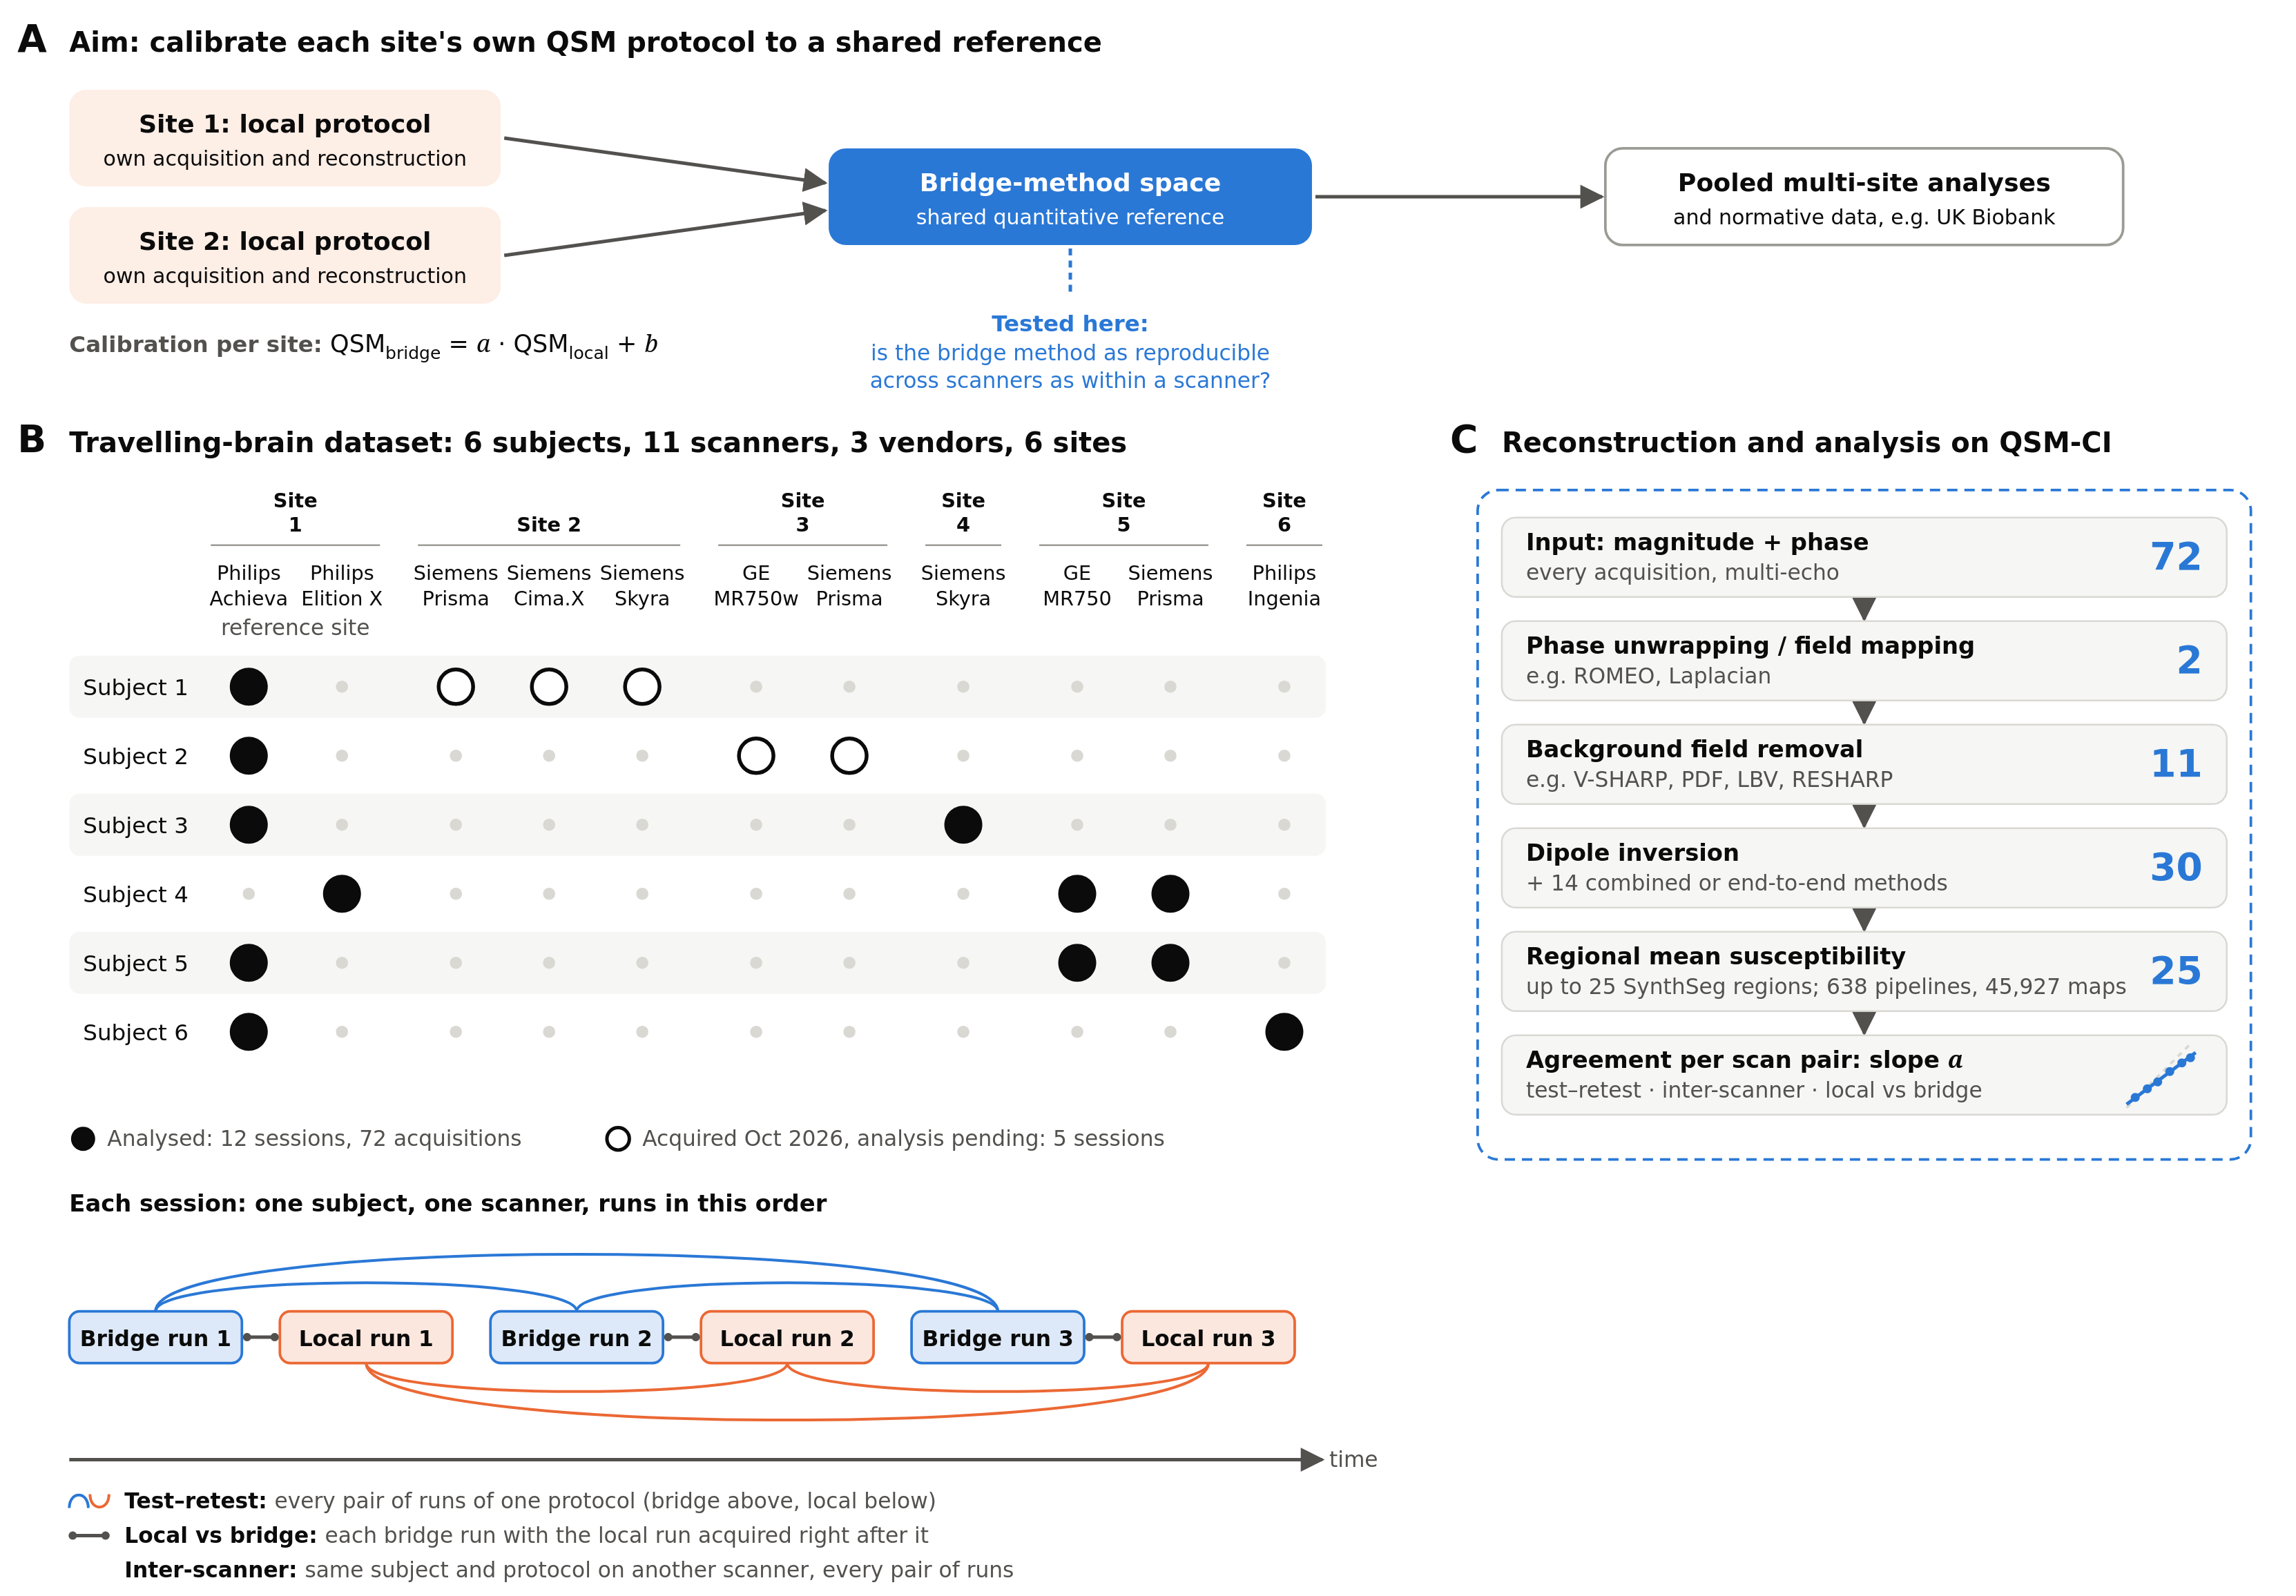

In [14]:
Image('figures/fig1_study_design.png', width=900)

### Figure 2: representative images

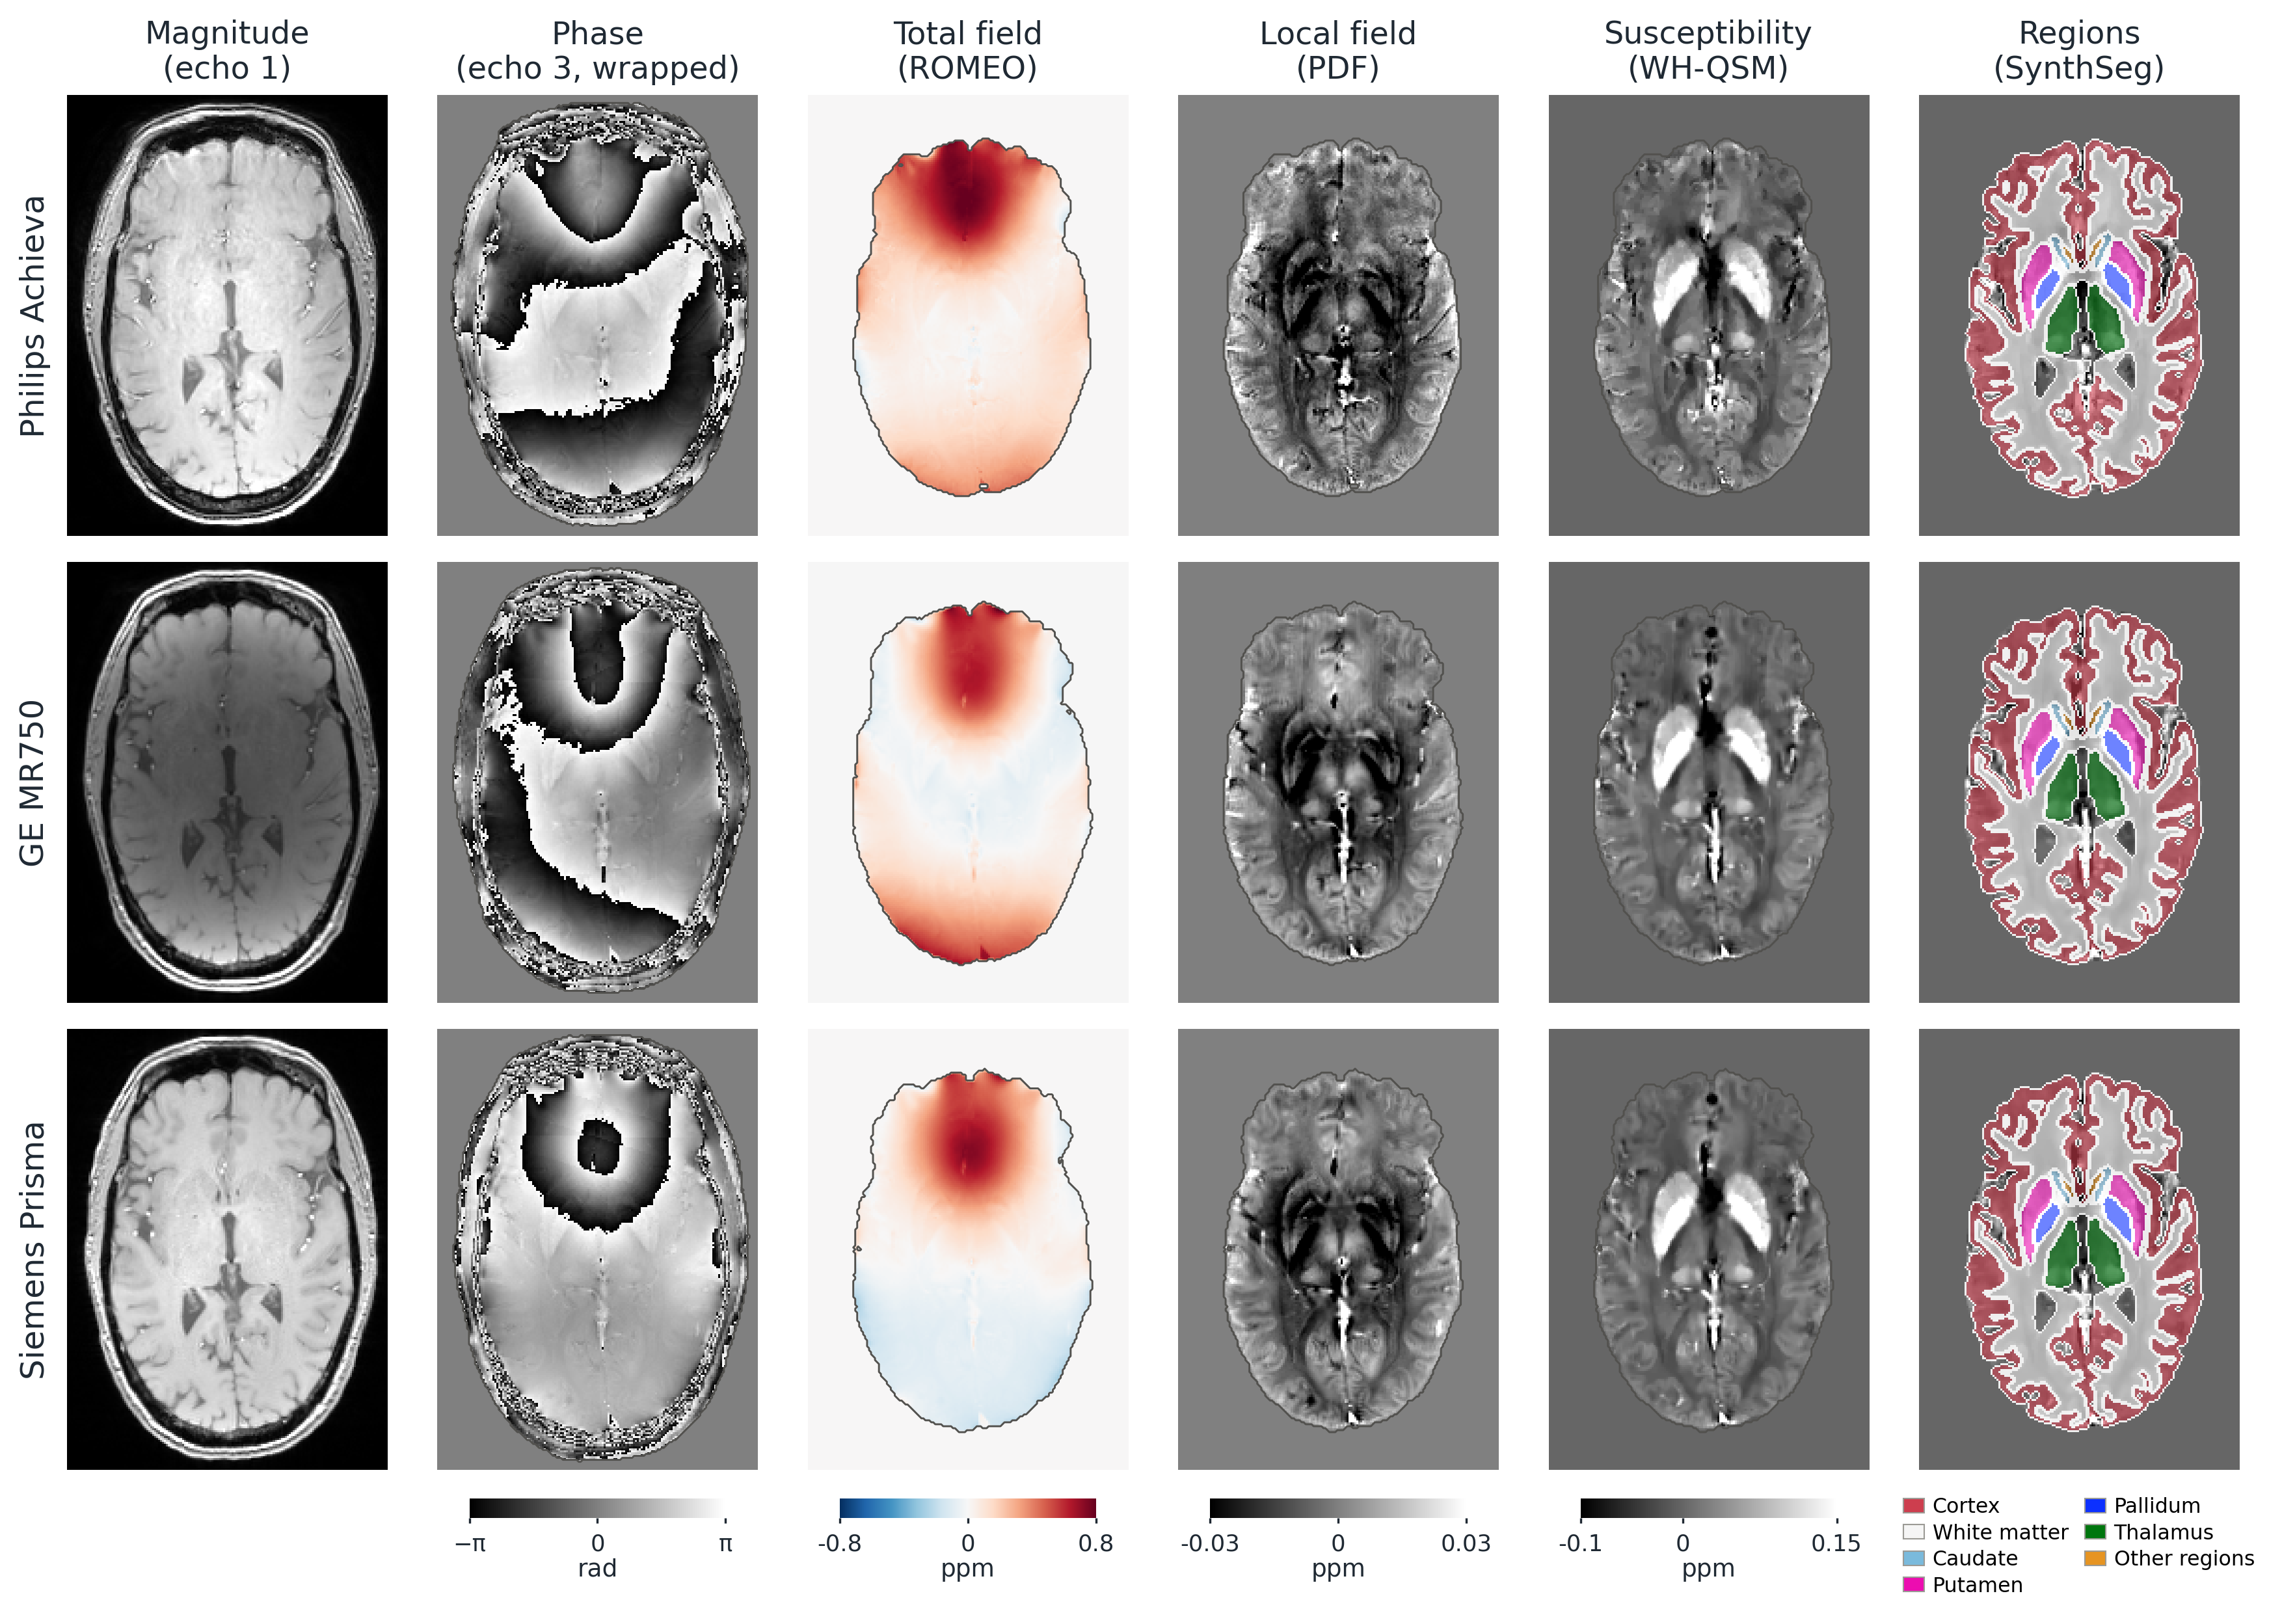

In [15]:
Image('figures/fig2_representative_images.png', width=900)

### Figure 3: agreement between scans

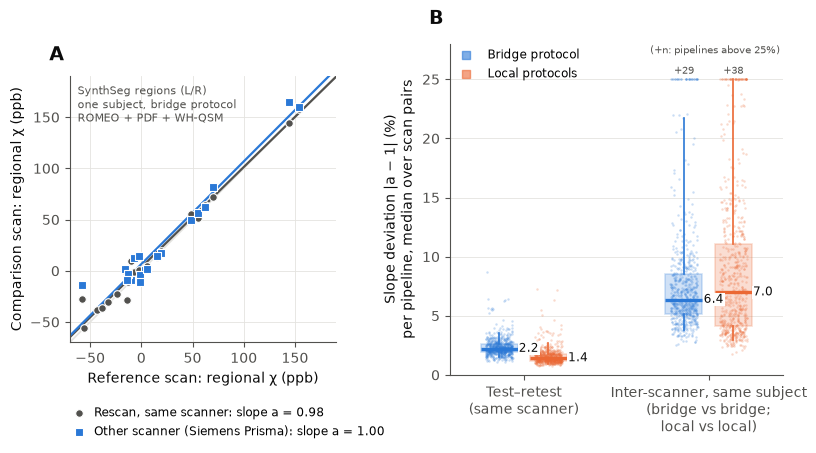

In [16]:
import fig3_agreement
fig3_agreement.make(reg, fits);

### Figure 4: sources of variability

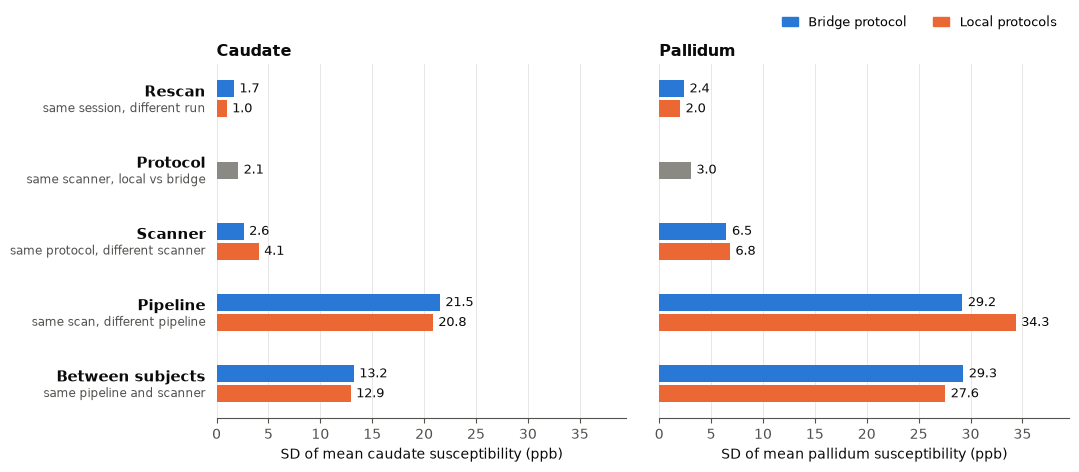

In [17]:
import fig4_sources_of_variability
fig4_sources_of_variability.make(reg);

### Figure 5: pipeline dependence of inter-scanner agreement on QSM-CI

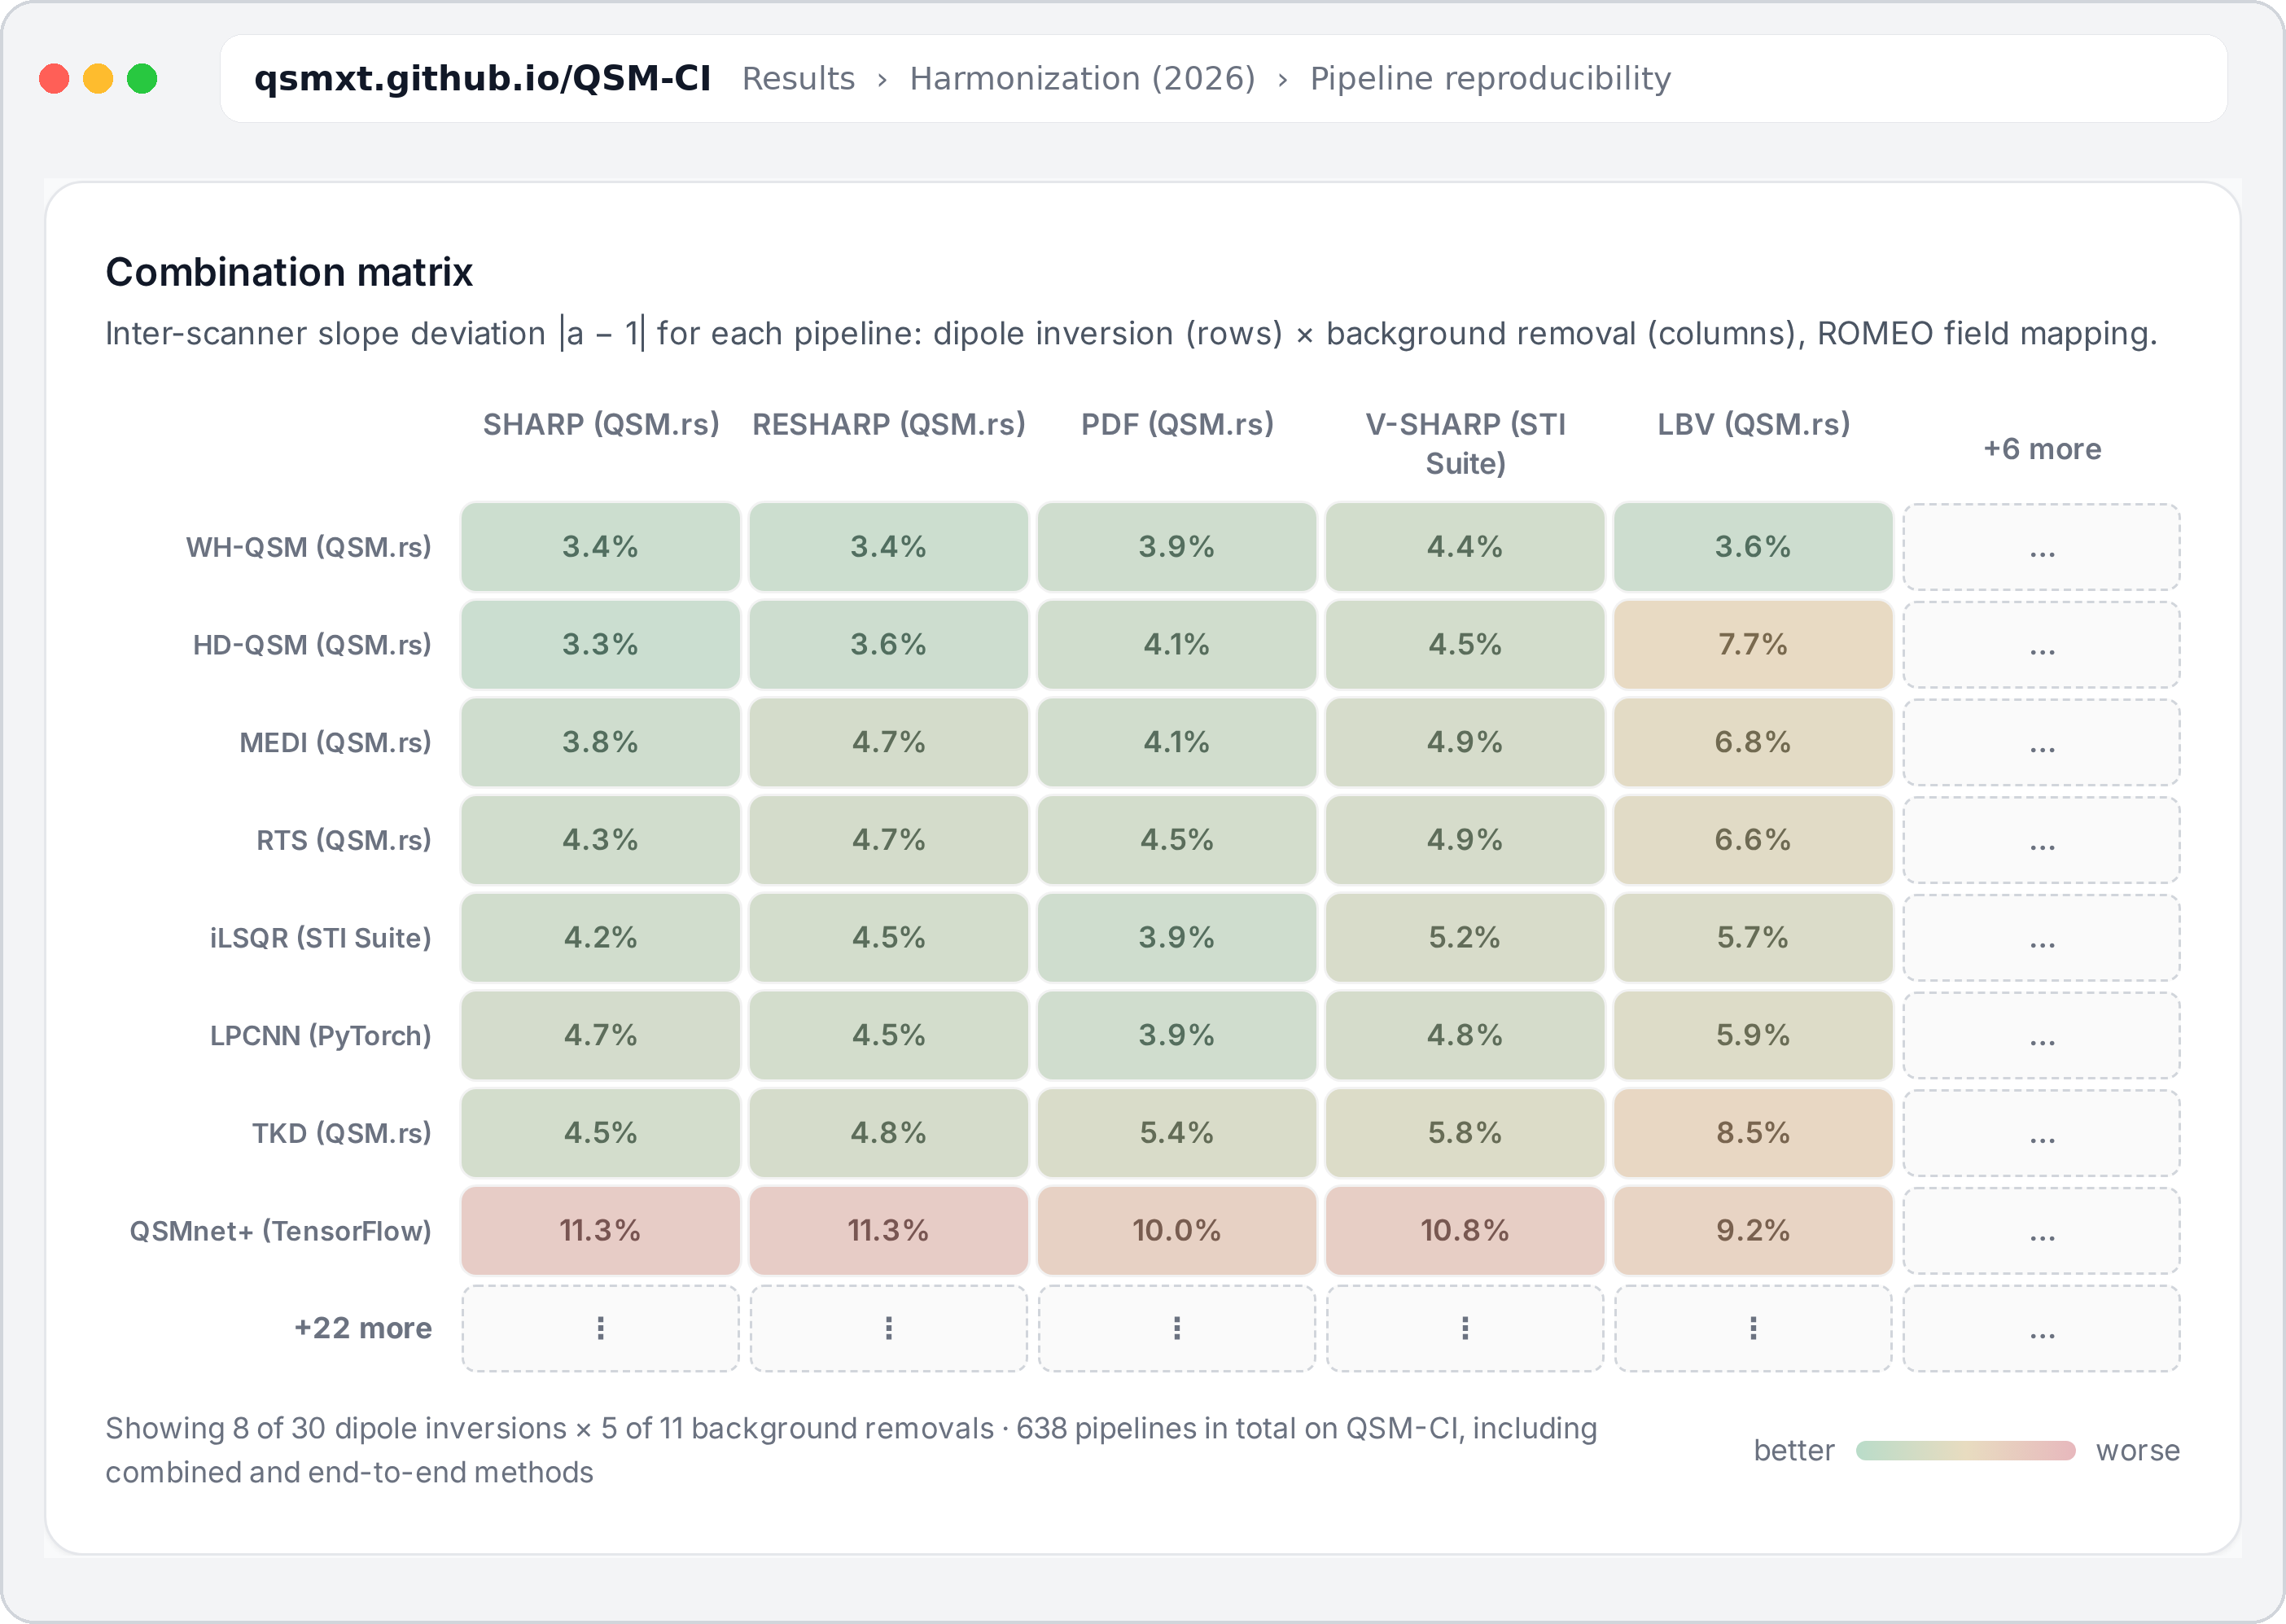

In [18]:
Image('figures/fig5_qsmci.png', width=800)

The same grid computed from the data: inter-scanner median |a − 1| (%) over all scan pairs, ROMEO field mapping.

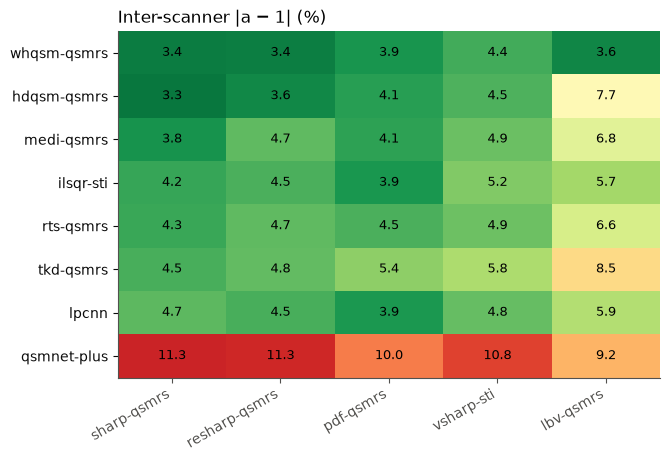

In [19]:
import matplotlib.pyplot as plt
isc_all = 100 * ok[ok.comparison == 'inter_scanner'].groupby('pipeline').abs_slope_dev.median()
grid = pd.DataFrame([[isc_all.get(f'romeo-qsmrs+{b}+{d}') for b in emtp.FIG5_BFR] for d in emtp.FIG5_DIPOLE],
                    index=emtp.FIG5_DIPOLE, columns=emtp.FIG5_BFR)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.imshow(grid.values, cmap='RdYlGn_r', vmin=3, vmax=12, aspect='auto')
for (i, j), v in np.ndenumerate(grid.values):
    ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=9)
ax.set_xticks(range(len(grid.columns)), grid.columns, rotation=30, ha='right'); ax.set_yticks(range(len(grid)), grid.index)
ax.set_title('Inter-scanner |a − 1| (%)', loc='left'); plt.show()